Datasets library to initially load the dataset from Hugging Faces. For ease of reproducing the experiment

In [82]:
# from datasets import load_dataset

# dataset = load_dataset("Console-AI/IT-helpdesk-synthetic-tickets")

# print(dataset)

In [83]:
import sys
print(sys.executable)

c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Scripts\python.exe


Importing as a dataframe enables applying pandas compatible functions to the dataframe rather than just a CSV

In [84]:
import pandas as pd
df = pd.read_csv('../data/processed/processed.csv')
print(df.keys())

Index(['id', 'subject', 'description', 'priority', 'category', 'createdAt',
       'requesterEmail'],
      dtype='str')


10 Records were removed from the small dataset because they belonged to classes with very few examples, such as "Infrastructure" so for ease of training they were removed. Originally the set contained 500 records

In [85]:
print(df.shape)

(490, 7)


In [86]:
df.head()

,id,subject,description,priority,category,createdAt,requesterEmail
0,1aiu3lrqi,Hey IT! Our network printer keeps disconnecting.,Hey IT! Our network printer keeps disconnectin...,Medium,Network,2024-10-28T18:36:55.004Z,jane.doe@acme.co
1,kz5mjjpox,Re: [Acme IT] Re: Ticket #98765 - Access Issue...,This is a follow-up to your previous request #...,High,Network,2024-10-28T18:36:56.156Z,user123@acme.co
2,86eza0fwq,Software Conflict Causing App Crashes,Hey team! :wave: We're experiencing some inter...,High,Software,2024-10-28T18:36:54.644Z,user@acme.co
3,jtw509e3n,j.doe@acme.co Google Calendar Setup Assistance,We need to set up a new Google Calendar for te...,Medium,Software,2024-10-28T18:36:54.524Z,j.doe@acme.co
4,tso616mbn,Software Access: Asana Project for Jordan Smith,Jordan Smith is part of the Project Management...,Medium,Software,2024-10-28T18:36:54.816Z,jordan.smith@acme.co


The following functions have been commented out, but they were for understanding the structure of the datset

In [87]:
# shows first few records of dataframe
# df.head()

# for size of table
# df.shape

# for names of each column
# df.columns

# generic info
# df.info()

# number of empties boxes in records?
# df.isnull().sum()

# number of each category
df["category"].value_counts()

# number of each priority
# df["priority"].value_counts()

# picks 10 random records and shows the corresponding fields
# df[["subject", "description", "category"]].sample(10)



category
Software         231
Account           71
Network           68
Security          42
Communication     24
Hardware          22
RemoteWork        20
Training          12
Name: count, dtype: int64

In [88]:
df[["subject", "description", "category"]].sample(
    10,
    random_state=234
)

df["subject_length"]=df["subject"].str.split().str.len()
df["description_length"]=df["description"].str.split().str.len()

df[["subject_length", "description_length"]].describe()

,subject_length,description_length
count,490.000000,490.000000
mean,6.573469,59.924490
std,2.572409,58.655457
min,3.000000,3.000000
25%,5.000000,28.000000
50%,6.000000,45.000000
75%,7.000000,68.000000
max,23.000000,606.000000


In [89]:
print("Duplicate subjects:")
print(df["subject"].duplicated().sum())

print("Duplicate descriptions:")
print(df["description"].duplicated().sum())

print("Duplicate subject + description:")
print(
    df.duplicated(
        subset=["subject", "description"]
    ).sum()
)

Duplicate subjects:
11
Duplicate descriptions:
3
Duplicate subject + description:
0


In [90]:
# Metrics to compare subject length Vs description length
# Large differences in lengths means it's likely favourable to keep both

# df.groupby("category")[
#     ["subject_length", "description_length"]
# ].mean().round(2)

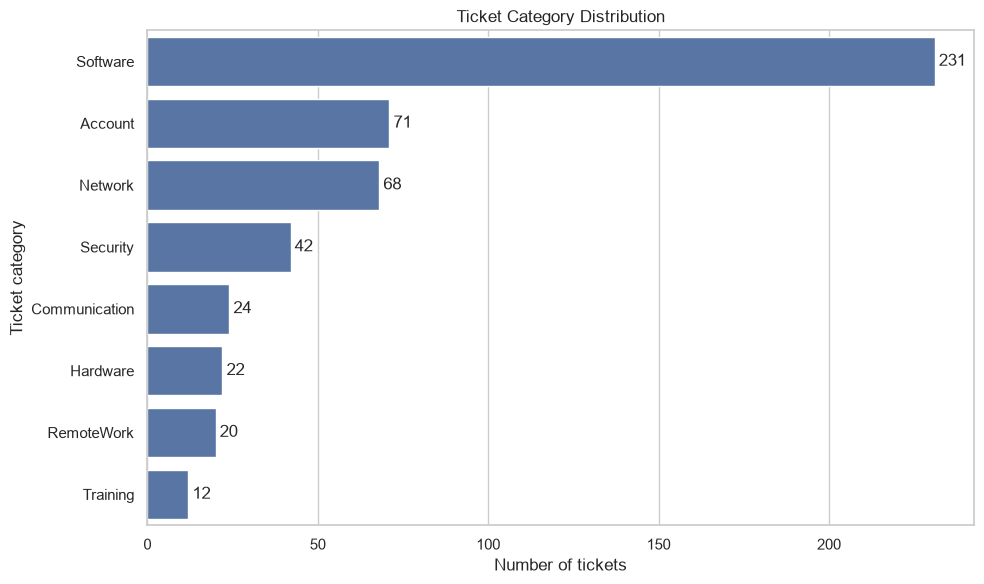

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))

ax=sns.countplot(
      data=df,
      y = "category",
      order=df["category"].value_counts().index
)

ax.bar_label(ax.containers[0], padding=3)

plt.xlabel("Number of tickets")
plt.ylabel("Ticket category")
plt.title("Ticket Category Distribution")

plt.tight_layout()
plt.show()

So Tickets falling under the "Software" category take the majority of the tickeets in this dataset. We need to approach the dataset carefully so that models won't just predict "Software" and get away with a seemingly high prediction accuracy.

It's been decided that we train a model using the subject content as well as the content of the ticket description. So we combine these into a separate column so it is easier to feed the model with input data

In [92]:
# This will the be text fed into the prediction algorithm

df["text"] = (
    df["subject"].str.strip() + " " + df["description"].str.strip()
)

df.head()

,id,subject,description,priority,category,createdAt,requesterEmail,subject_length,description_length,text
0,1aiu3lrqi,Hey IT! Our network printer keeps disconnecting.,Hey IT! Our network printer keeps disconnectin...,Medium,Network,2024-10-28T18:36:55.004Z,jane.doe@acme.co,7,43,Hey IT! Our network printer keeps disconnectin...
1,kz5mjjpox,Re: [Acme IT] Re: Ticket #98765 - Access Issue...,This is a follow-up to your previous request #...,High,Network,2024-10-28T18:36:56.156Z,user123@acme.co,13,88,Re: [Acme IT] Re: Ticket #98765 - Access Issue...
2,86eza0fwq,Software Conflict Causing App Crashes,Hey team! :wave: We're experiencing some inter...,High,Software,2024-10-28T18:36:54.644Z,user@acme.co,5,40,Software Conflict Causing App Crashes Hey team...
3,jtw509e3n,j.doe@acme.co Google Calendar Setup Assistance,We need to set up a new Google Calendar for te...,Medium,Software,2024-10-28T18:36:54.524Z,j.doe@acme.co,5,30,j.doe@acme.co Google Calendar Setup Assistance...
4,tso616mbn,Software Access: Asana Project for Jordan Smith,Jordan Smith is part of the Project Management...,Medium,Software,2024-10-28T18:36:54.816Z,jordan.smith@acme.co,7,22,Software Access: Asana Project for Jordan Smit...


In [93]:
for category in df["category"].unique():

    print("\n" + "=" * 60)
    print(category)
    print("=" * 60)

    examples = df[df["category"] == category][
        ["subject", "description"]
    ].head(3)

    for _, row in examples.iterrows():
        print("\nSUBJECT:")
        print(row["subject"])

        print("\nDESCRIPTION:")
        print(row["description"])


Network

SUBJECT:
Hey IT! Our network printer keeps disconnecting.

DESCRIPTION:
Hey IT! Our network printer keeps disconnecting intermittently and requires manual IP reconfiguration each time. It's becoming quite a hassle, especially during busy hours. A few folks in the office have mentioned they're experiencing the same issue. Could you look into this? Thanks!

SUBJECT:
Re: [Acme IT] Re: Ticket #98765 - Access Issue with Shared Network Drive

DESCRIPTION:
This is a follow-up to your previous request #98765 "Access Issue with Shared Network Drive"

Hello!

I'm having trouble accessing the shared network drive. It used to work fine, but now I'm getting permission errors that seem quite complex. I believe it might require a detailed audit and manual adjustment to resolve.

Here's a screenshot of the error message (https://acme.co/share/error-screenshot) . I've tried basic troubleshooting steps like checking my network connection and restarting my computer.

Thanks, and please let me k

Now we'll make a baseline model from the sklearn library. The most common train validation test split is 70/15/15 so we'll choose this for now

In [94]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["category"]

# Choose a 70/15/15 split for Train test and val splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state= 234
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state= 234
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


Training: 343
Validation: 73
Test: 74


## Baseline Model

In [95]:
# Make a baseline model, that picks the most common category
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_val)

print("Accuracy:", accuracy_score(y_val, dummy_preds))
print("Weighted F1:", f1_score(y_val, dummy_preds, average="weighted"))
print("Macro F1:", f1_score(y_val, dummy_preds, average="macro"))


Accuracy: 0.4657534246575342
Weighted F1: 0.2959928306234797
Macro F1: 0.0794392523364486


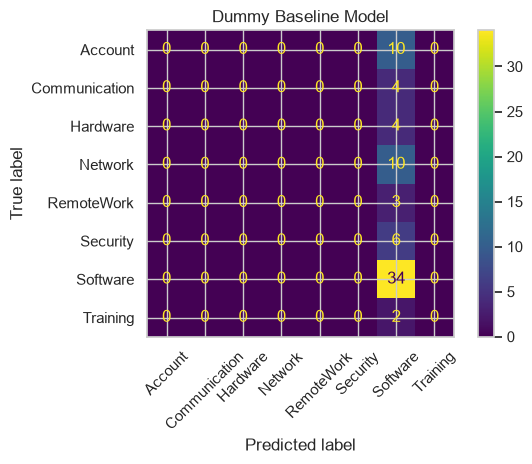

In [96]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    dummy_preds,
    xticks_rotation=45
)

plt.title("Dummy Baseline Model")
plt.tight_layout()
plt.show()

As expected by the dummy model. By simply classifying every ticket as the most common appearing category, the model got an accuracy of 0.45 amongst 8 possible categories. We'll challenge this approach with a simple logistic regression model using term frequencies to convert words into numerical values instead. This conversion method involves multiplying the proportion of times the same word appears in a sample with how many documents contain the word over the total number of documents. The higher the value, the more meaningful it is, whereas a low value would be seen as a filler word like "and".

## Term Frequency and inverse document frequency (TFIDF) Implementation

In [97]:
# model that extracts important words and bigrams
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1,2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)

print(X_train_tfidf.shape)
print(X_val_tfidf.shape)

# print(X_train_tfidf[0])
# print(X_val_tfidf[0])

feature_names = vectorizer.get_feature_names_out()

print(feature_names[:50])
print("Number of features:", len(feature_names))



(343, 3460)
(73, 3460)
['00' '00 00' '00 000' '00 07' '00 am' '00 cst' '00 pst' '00 request'
 '00 review' '000' '000 05' '000 07' '01' '0199' '05' '05 00' '06t11'
 '06t11 00' '06t11 30' '07' '07 00' '07 15t09' '08' '09' '09 00' '09 15'
 '10' '10 00' '10 15' '10 2023' '10 30' '10 45' '10001' '101' '101 faq'
 '11' '12' '123' '123 4567' '123 innovation' '1234' '1234 elm' '12345'
 '12345 you' '12345abcde67890fghij' '12345abcde67890fghij effective' '14'
 '14 30' '14 45' '15']
Number of features: 3460


In [98]:
# put vectors form tfidf and put into logistic
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state= 234
)

model.fit(X_train_tfidf, y_train)
val_preds = model.predict(X_val_tfidf)

In [99]:
from sklearn.metrics import classification_report

print("Accuracy:", accuracy_score(y_val, val_preds))
print("Weighted F1:", f1_score(y_val, val_preds, average="weighted"))
print("Macro F1:", f1_score(y_val, val_preds, average="macro"))

print(classification_report(y_val, val_preds))

Accuracy: 0.6027397260273972
Weighted F1: 0.5162100456621005
Macro F1: 0.2885416666666667
               precision    recall  f1-score   support

      Account       1.00      0.20      0.33        10
Communication       0.00      0.00      0.00         4
     Hardware       0.00      0.00      0.00         4
      Network       1.00      0.50      0.67        10
   RemoteWork       0.00      0.00      0.00         3
     Security       0.75      0.50      0.60         6
     Software       0.55      1.00      0.71        34
     Training       0.00      0.00      0.00         2

     accuracy                           0.60        73
    macro avg       0.41      0.28      0.29        73
 weighted avg       0.59      0.60      0.52        73



c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

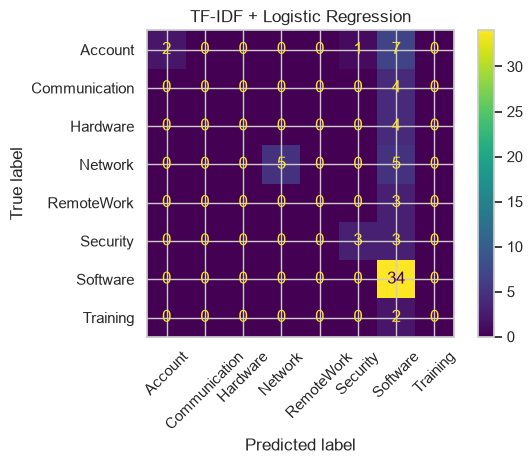

In [100]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_preds,
    xticks_rotation=45
)

plt.title("TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()

This method did improve metrics, but not by a substantial amount, with the confusion matrix suggesting the model assigns the category "software" to every ticket that doesn't have an obvious giveaway like tickets for "Network" with keywords like "Internet" and "Network". What if we force the class weightings to be balanced instead? so categories with less tickets are treated as less likely as larger categories

In [101]:
balanced_logistic = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=234
)

balanced_logistic.fit(X_train_tfidf, y_train)
balanced_preds = balanced_logistic.predict(X_val_tfidf)

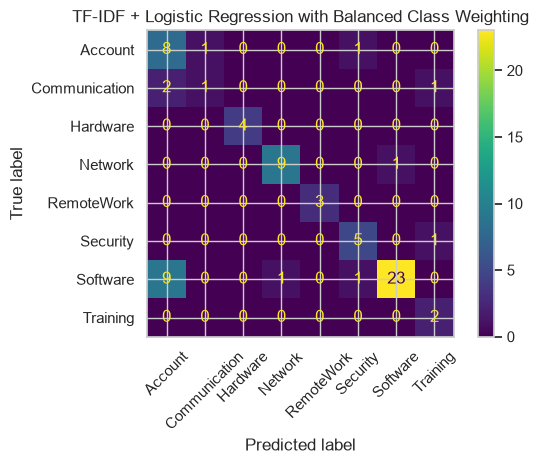

In [102]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    balanced_preds,
    xticks_rotation=45
)

plt.title("TF-IDF + Logistic Regression with Balanced Class Weighting")
plt.tight_layout()
plt.show()

Well the results are now a lot more promising. In this test run, most tickets were assigned to their original category, but now a good portion of software tickets are classified as "Account". This is perhaps due to software orignally having a larger number of tickets, meaning identifying a software ticket as an account ticket is less penalising than vice versa. Overall though, this test run correctly identified roughly three quarters of the test ticket set.

In [103]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        balanced_preds,
        digits=3
    )
)

               precision    recall  f1-score   support

      Account      0.421     0.800     0.552        10
Communication      0.500     0.250     0.333         4
     Hardware      1.000     1.000     1.000         4
      Network      0.900     0.900     0.900        10
   RemoteWork      1.000     1.000     1.000         3
     Security      0.714     0.833     0.769         6
     Software      0.958     0.676     0.793        34
     Training      0.500     1.000     0.667         2

     accuracy                          0.753        73
    macro avg      0.749     0.807     0.752        73
 weighted avg      0.823     0.753     0.764        73



In [104]:
results = []

results.append({
    "model": "Dummy Baseline",
    "accuracy": accuracy_score(y_val, dummy_preds),
    "weighted_f1": f1_score(y_val, dummy_preds, average="weighted"),
    "macro_f1": f1_score(y_val, dummy_preds, average="macro")
})

results.append({
    "model": "TF-IDF + Logistic Regression",
    "accuracy": accuracy_score(y_val, val_preds),
    "weighted_f1": f1_score(y_val, val_preds, average="weighted"),
    "macro_f1": f1_score(y_val, val_preds, average="macro")
})

results.append({
    "model": "TF-IDF + Logistic Regression with Balanced Classes",
    "accuracy": accuracy_score(y_val, balanced_preds),
    "weighted_f1": f1_score(y_val, balanced_preds, average="weighted"),
    "macro_f1": f1_score(y_val, balanced_preds, average="macro")
})


In [105]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,weighted_f1,macro_f1
0,Dummy Baseline,0.465753,0.295993,0.079439
1,TF-IDF + Logistic Regression,0.602740,0.516210,0.288542
2,TF-IDF + Logistic Regression with Balanced Cla...,0.753425,0.763902,0.751757


Comparing the TF-IDF to the baseline model we see that there's a small improvement, but after treating class weightings as more balanced all of a sudden we get some reasonable results. The confusion matrix shows a stronger leading diagonal than the prior examples. A large source of errors from the balanced model is from misassigning software tickets as account tickets, which could suggest overlap in topics between the two categories, or the case of taking the lower penalty for identifying a software ticket as an account ticket, than vice versa.

We could check the contents of tickets that the model misclassed as account rather than software.

In [106]:
error_df = pd.DataFrame({
    "text": X_val,
    "actual": y_val,
    "predicted": balanced_preds
})

software_as_account = error_df[
    (error_df["actual"] == "Software") &
    (error_df["predicted"] == "Account")
]

software_as_account[["text", "actual", "predicted"]]

,text,actual,predicted
140,Access Request for ZDesk Agent Console I used ...,Software,Account
462,Audit trail for Productiv AppCenter request fo...,Software,Account
99,Access Request for Lightroom Editing Tools I n...,Software,Account
173,Access Request for Asana Task Board Requesting...,Software,Account
314,Access Request for T-Card Project Management T...,Software,Account
193,Access Request for Adobe Spark Design Tools Hi...,Software,Account
255,JIRA Access Request Hello - I need access to t...,Software,Account
368,"Access Request for DBox Sync Feature Hi,\r\n\r...",Software,Account
417,"Access Request for Adobe Bridge Hi,\r\n\r\nI n...",Software,Account


Well from the 9 software tickets that were misidentified as account tickets, we can see they all involve an "Access request" to named software like adobe which due to ambiguity could be seen as an account issue, like granting permissions. This points towards a label overlap in the dataset.

If we extract the kind of words that commonly appeared in account and software, we might be able to see where the ambiguity lies. This can help us navigate these issues with better models later on.

In [107]:
import numpy as np

feature_names = vectorizer.get_feature_names_out()

classes = balanced_logistic.classes_

for target_class in ["Account", "Software"]:

    class_index = np.where(classes == target_class)[0][0]

    coefficients = balanced_logistic.coef_[class_index]

    top_indices = np.argsort(coefficients)[-15:][::-1]

    print(f"\nTop features for {target_class}")

    for idx in top_indices:
        print(
            feature_names[idx],
            round(coefficients[idx], 3)
        )


Top features for Account
access 1.44
dbox 1.149
password 1.001
access request 0.955
account 0.822
gh 0.708
collaboration 0.693
access to 0.693
request 0.678
sf 0.666
reset 0.66
password reset 0.585
sales 0.575
request for 0.532
to the 0.488

Top features for Software
data 0.853
cloud 0.826
tools 0.616
based 0.58
adobe 0.574
cloud based 0.556
enterprise cloud 0.543
document 0.537
management 0.534
our 0.457
our enterprise 0.457
issues with 0.438
with our 0.433
issues 0.413
enterprise 0.405


Many words you would expect appear as features for Account tickets, like "access request" as mentioned prior. And these phrases end up appearing in tickets that have been assigned as software.

For now we'll move on to a Pytorch implementation instead. We'll use some neural models, but we'll build one for regular cross entropy loss, and another for weighted cross entropy loss, as we saw a big improvement between the two in the TF-IDF implementation.

With this we can test whether class weighting will affect Account ticket recall at the cost of Software tickets being misidentified as Account tickets.

## Pytorch Neural Network Implementation

We'll make use of the Pytorch Library to implement a simple neural classifier. 
The classifier will follow the pipeline of:

Ticket text -> Tokenisation -> Integer Encoding -> Padding -> Embedding -> Pooling -> Fully Connected NN -> Category Prediction

In [108]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
import numpy as np
import torch

torch.manual_seed(234)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes = classes,
    y=y_train
)

# converts weights into a tenosr, because CrossEntropyLoss expects a tensor as a parameter
class_weights = torch.tensor(
    weights, 
    dtype = torch.float32
).to(device)

criterion = torch.nn.CrossEntropyLoss(
    weight = class_weights
)

# We need to categories into integer class IDs for the classification loss (labelled from 0 to 7)
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)
print(y_train_encoded[:10])

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

Device: cuda
['Account' 'Communication' 'Hardware' 'Network' 'RemoteWork' 'Security'
 'Software' 'Training']
[3 6 6 6 6 6 3 6 6 6]
PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True


In [109]:
from collections import Counter
MAX_LENGTH = 100
# simple tokenizing by splitting text into words
def tokenize(text):
    return text.lower().split()

# We build the training data from X_train because this is the training data, any other data could leak.
word_count = Counter()
for text in X_train:
    tokens  = tokenize(text)
    word_count.update(tokens)

# vocab stores special tokens that we use for unknown vocabulary that may only appear in the validation or test split
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

# Here we give each word a numerical representation 
for word, count in word_count.items():
    if count >= 2:
        vocab[word] = len(vocab)


def encode_text(text, vocab):
    tokens = tokenize(text)

    return [vocab.get(token, vocab["<UNK>"]) for token in tokens]

# This function just ensures each ticket has the same dimensions so we dont have issues with batches later
def encode_with_pad(text, vocab, max_length=100):
    encoded = encode_text(text, vocab)
    encoded = encoded[:max_length]

    padding = max_length-len(encoded)
    encoded += [vocab["<PAD>"]] * padding
    return encoded




We'll define a class that lays out the structure of each split such that pytorch can safely handle the ticket data in expected format

In [110]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

class TicketDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_length):

        self.texts = list(texts)
        self.labels = labels
        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    # retrieves the contents of a ticket and its category
    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        encoded = encode_with_pad(text, self.vocab, self.max_length)

        return(torch.tensor(encoded, dtype=torch.long), torch.tensor(label, dtype=torch.long))


train_dataset = TicketDataset(
    X_train,
    y_train_encoded,
    vocab,
    MAX_LENGTH
)

val_dataset = TicketDataset(
    X_val,
    y_val_encoded,
    vocab,
    MAX_LENGTH
)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

texts, labels = next(iter(train_loader))

print("Texts:", texts.shape)
print("Labels:", labels.shape)


Texts: torch.Size([32, 100])
Labels: torch.Size([32])


Using Pytorch's Neural network library we can implement a simple linear model

In [111]:
import torch.nn as nn
class TicketClassifer(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.relu = nn.ReLU()  
        self.droupout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        mask = (x != 0).unsqueeze(-1)
        embedded = embedded*mask
        summed = embedded.sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1)
        pooled = summed/lengths

        x = self.fc1(pooled)
        x = self.relu(x)
        x = self.droupout(x)

        logits = self.fc2(x)
        return logits


print(torch.cuda.is_available())

True


In [112]:
NUM_CLASSES = len(label_encoder.classes_)

model = TicketClassifer(vocab_size=len(vocab), embedding_dim=64, hidden_dim=64, num_classes=NUM_CLASSES, dropout=0.2)
model = model.to(device)


batch_x, batch_y = next(iter(train_loader))
batch_x = batch_x.to(device)
outputs = model(batch_x)

print(batch_x.shape)
print(outputs.shape)


torch.Size([32, 100])
torch.Size([32, 8])


## Training the Unweighted Pytorch Model

In [113]:
import torch.optim as optim
from sklearn.metrics import f1_score

NUM_EPOCHS = 50
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_x, batch_y in loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = model(batch_x)

        loss = criterion(logits, batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)

        predictions = logits.argmax(dim=1)

        correct += (predictions == batch_y).sum().item()
        total += batch_y.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_x)

            loss = criterion(logits, batch_y)

            total_loss += loss.item() * batch_x.size(0)

            predictions = logits.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch_y.cpu().numpy()
            )

    avg_loss = total_loss / len(loader.dataset)

    accuracy = (
        sum(
            p == y
            for p, y in zip(all_predictions, all_labels)
        )
        / len(all_labels)
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        avg_loss,
        accuracy,
        weighted_f1,
        macro_f1
    )

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_weighted_f1": [],
    "val_macro_f1": []
}


best_val_loss = float("inf")
patience = 5
epochs_without_improvement = 0
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_weighted_f1,
        val_macro_f1
    ) = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_weighted_f1"].append(val_weighted_f1)
    history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.3f} | "
        f"Val Acc: {val_accuracy:.3f} | "
        f"Weighted F1: {val_weighted_f1:.3f} | "
        f"Macro F1: {val_macro_f1:.3f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            "../models/pytorch_unweighted.pt"
        )

    else:

        epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping.")
            break

Epoch 01 | Train Loss: 2.1030 | Val Loss: 2.0493 | Train Acc: 0.041 | Val Acc: 0.123 | Weighted F1: 0.160 | Macro F1: 0.082
Epoch 02 | Train Loss: 2.0146 | Val Loss: 1.9547 | Train Acc: 0.335 | Val Acc: 0.466 | Weighted F1: 0.299 | Macro F1: 0.080
Epoch 03 | Train Loss: 1.9119 | Val Loss: 1.8503 | Train Acc: 0.493 | Val Acc: 0.466 | Weighted F1: 0.296 | Macro F1: 0.079
Epoch 04 | Train Loss: 1.8007 | Val Loss: 1.7409 | Train Acc: 0.475 | Val Acc: 0.466 | Weighted F1: 0.296 | Macro F1: 0.079
Epoch 05 | Train Loss: 1.6752 | Val Loss: 1.6679 | Train Acc: 0.478 | Val Acc: 0.466 | Weighted F1: 0.296 | Macro F1: 0.079
Epoch 06 | Train Loss: 1.5711 | Val Loss: 1.6515 | Train Acc: 0.472 | Val Acc: 0.466 | Weighted F1: 0.296 | Macro F1: 0.079
Epoch 07 | Train Loss: 1.5335 | Val Loss: 1.6548 | Train Acc: 0.472 | Val Acc: 0.466 | Weighted F1: 0.296 | Macro F1: 0.079
Epoch 08 | Train Loss: 1.4672 | Val Loss: 1.6167 | Train Acc: 0.490 | Val Acc: 0.466 | Weighted F1: 0.296 | Macro F1: 0.079
Epoch 09

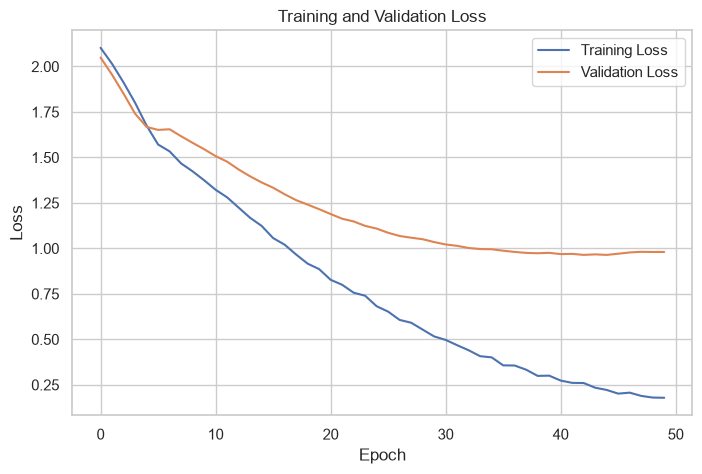

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

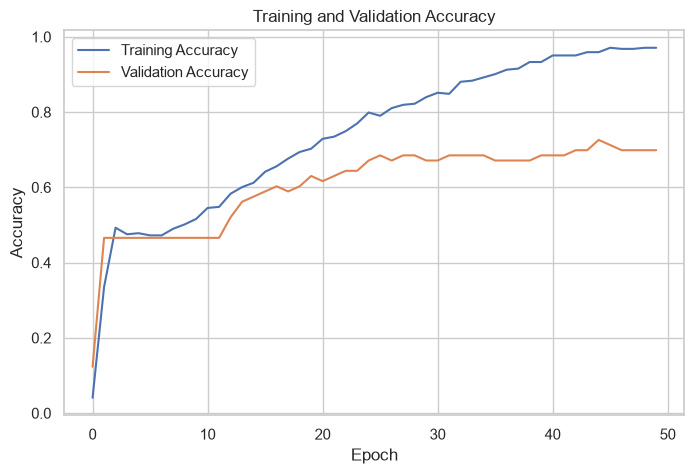

In [115]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

               precision    recall  f1-score   support

      Account      0.533     0.800     0.640        10
Communication      0.000     0.000     0.000         4
     Hardware      1.000     0.500     0.667         4
      Network      0.643     0.900     0.750        10
   RemoteWork      1.000     0.333     0.500         3
     Security      0.833     0.833     0.833         6
     Software      0.848     0.824     0.836        34
     Training      0.000     0.000     0.000         2

     accuracy                          0.726        73
    macro avg      0.607     0.524     0.528        73
 weighted avg      0.721     0.726     0.705        73



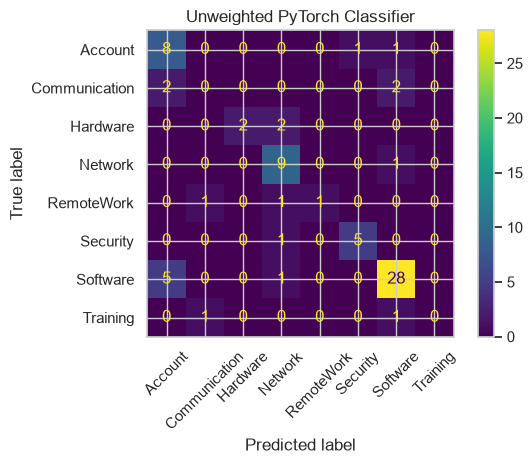

In [116]:
model.load_state_dict(
    torch.load(
        "../models/pytorch_unweighted.pt",
        weights_only=True
    )
)

def get_predictions(model, loader, device):

    model.eval()

    predictions = []
    labels = []

    with torch.no_grad():

        for batch_x, batch_y in loader:

            batch_x = batch_x.to(device)

            logits = model(batch_x)

            preds = logits.argmax(dim=1)

            predictions.extend(
                preds.cpu().numpy()
            )

            labels.extend(
                batch_y.numpy()
            )

    return labels, predictions

val_true, val_pred = get_predictions(
    model,
    val_loader,
    device
)

true_names = label_encoder.inverse_transform(
    val_true
)

pred_names = label_encoder.inverse_transform(
    val_pred
)

from sklearn.metrics import classification_report

print(
    classification_report(
        true_names,
        pred_names,
        digits=3
    )
)

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    true_names,
    pred_names,
    xticks_rotation=45
)

plt.title("Unweighted PyTorch Classifier")
plt.tight_layout()
plt.show()



## second model

In [117]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(label_encoder.classes_)),
    y=y_train_encoded
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print(class_weights)

for category, weight in zip(
    label_encoder.classes_,
    class_weights.cpu().numpy()
):
    print(f"{category:15s}: {weight:.3f}")


tensor([0.8575, 2.5221, 2.8583, 0.8932, 3.0625, 1.4784, 0.2647, 5.3594],
       device='cuda:0')
Account        : 0.858
Communication  : 2.522
Hardware       : 2.858
Network        : 0.893
RemoteWork     : 3.062
Security       : 1.478
Software       : 0.265
Training       : 5.359


Epoch 01 | Train Loss: 2.0758 | Val Loss: 2.0728 | Train Acc: 0.137 | Val Acc: 0.151 | Weighted F1: 0.051 | Macro F1: 0.081
Epoch 02 | Train Loss: 2.0551 | Val Loss: 2.0647 | Train Acc: 0.155 | Val Acc: 0.164 | Weighted F1: 0.073 | Macro F1: 0.177
Epoch 03 | Train Loss: 2.0425 | Val Loss: 2.0568 | Train Acc: 0.181 | Val Acc: 0.164 | Weighted F1: 0.073 | Macro F1: 0.177
Epoch 04 | Train Loss: 2.0232 | Val Loss: 2.0469 | Train Acc: 0.207 | Val Acc: 0.164 | Weighted F1: 0.073 | Macro F1: 0.177
Epoch 05 | Train Loss: 1.9962 | Val Loss: 2.0343 | Train Acc: 0.286 | Val Acc: 0.192 | Weighted F1: 0.121 | Macro F1: 0.187
Epoch 06 | Train Loss: 1.9800 | Val Loss: 2.0193 | Train Acc: 0.332 | Val Acc: 0.219 | Weighted F1: 0.184 | Macro F1: 0.236
Epoch 07 | Train Loss: 1.9470 | Val Loss: 2.0016 | Train Acc: 0.388 | Val Acc: 0.233 | Weighted F1: 0.217 | Macro F1: 0.224
Epoch 08 | Train Loss: 1.9165 | Val Loss: 1.9820 | Train Acc: 0.469 | Val Acc: 0.342 | Weighted F1: 0.346 | Macro F1: 0.319
Epoch 09

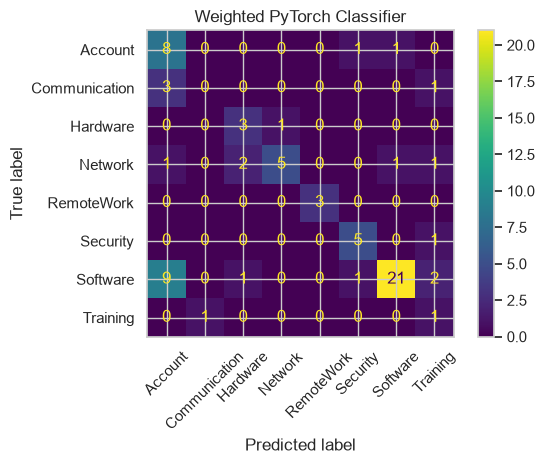

In [118]:
torch.manual_seed(234)

weighted_model = TicketClassifer(
    vocab_size=len(vocab),
    embedding_dim=64,
    hidden_dim=64,
    num_classes=NUM_CLASSES,
    dropout=0.2
).to(device)

weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

weighted_optimizer = torch.optim.Adam(
    weighted_model.parameters(),
    lr=1e-3
)

MODEL_PATH = "../models/pytorch_weighted.pt"

NUM_EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
epochs_without_improvement = 0

weighted_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_weighted_f1": [],
    "val_macro_f1": []
}

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        weighted_model,
        train_loader,
        weighted_criterion,
        weighted_optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_weighted_f1,
        val_macro_f1
    ) = evaluate(
        weighted_model,
        val_loader,
        weighted_criterion,
        device
    )

    weighted_history["train_loss"].append(train_loss)
    weighted_history["train_accuracy"].append(train_accuracy)
    weighted_history["val_loss"].append(val_loss)
    weighted_history["val_accuracy"].append(val_accuracy)
    weighted_history["val_weighted_f1"].append(val_weighted_f1)
    weighted_history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.3f} | "
        f"Val Acc: {val_accuracy:.3f} | "
        f"Weighted F1: {val_weighted_f1:.3f} | "
        f"Macro F1: {val_macro_f1:.3f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            weighted_model.state_dict(),
            MODEL_PATH
        )

    else:

        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

weighted_model.load_state_dict(
    torch.load(
        MODEL_PATH,
        weights_only=True
    )
)

weighted_model.to(device)

weighted_val_true, weighted_val_pred = get_predictions(
    weighted_model,
    val_loader,
    device
)

weighted_true_names = label_encoder.inverse_transform(
    weighted_val_true
)

weighted_pred_names = label_encoder.inverse_transform(
    weighted_val_pred
)


from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)

print(
    classification_report(
        weighted_true_names,
        weighted_pred_names,
        digits=3
    )
)

print(
    "Accuracy:",
    accuracy_score(
        weighted_true_names,
        weighted_pred_names
    )
)

print(
    "Weighted F1:",
    f1_score(
        weighted_true_names,
        weighted_pred_names,
        average="weighted"
    )
)

print(
    "Macro F1:",
    f1_score(
        weighted_true_names,
        weighted_pred_names,
        average="macro"
    )
)


from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    weighted_true_names,
    weighted_pred_names,
    labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("Weighted PyTorch Classifier")
plt.tight_layout()
plt.show()

In [126]:
from datasets import Dataset
from transformers import(
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

MODEL_NAME = "distilbert/distilbert-base-uncased"
print(len(X_train), len(X_val), len(X_test))
print(label_encoder.classes_)


343 73 74
['Account' 'Communication' 'Hardware' 'Network' 'RemoteWork' 'Security'
 'Software' 'Training']


In [127]:
train_dataset = Dataset.from_dict({
    "text": X_train.tolist(),
    "label": y_train_encoded.tolist()
})

val_dataset = Dataset.from_dict({
    "text": X_val.tolist(),
    "label": y_val_encoded.tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_test.tolist(),
    "label": y_test_encoded.tolist()
})

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

tokenized_train = train_dataset.map(tokenize, batched=True)
tokenized_val = val_dataset.map(tokenize, batched=True)
tokenized_test = test_dataset.map(tokenize, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# map integer labels to their nameres
id2label = {
    i: label
    for i, label in enumerate(label_encoder.classes_)
}

label2id = {
    label: i
    for i, label in enumerate(label_encoder.classes_)
}

id2label


Map:   0%|          | 0/343 [00:00<?, ? examples/s]

Map:   0%|          | 0/73 [00:00<?, ? examples/s]

Map:   0%|          | 0/74 [00:00<?, ? examples/s]

{0: 'Account',
 1: 'Communication',
 2: 'Hardware',
 3: 'Network',
 4: 'RemoteWork',
 5: 'Security',
 6: 'Software',
 7: 'Training'}

In [130]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = len(label_encoder.classes_),
    id2label = id2label,
    label2id = label2id
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "weighted_f1": f1_score(
            labels,
            predictions,
            average="weighted"
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }

c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\andyl\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [136]:
training_args = TrainingArguments(
    output_dir ="../models/first_distilbert_ticket_classifier",
    learning_rate = 2e-5,

    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,

    num_train_epochs = 3,
    weight_decay = 0.01,

    eval_strategy = "epoch",
    save_strategy = "epoch",

    load_best_model_at_end = True,
    metric_for_best_model = "macro_f1",
    greater_is_better = True,

    seed = 42,

    report_to = "none"
)

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

In [137]:
trainer.train()

val_metrics = trainer.evaluate(tokenized_val)
val_metrics

prediction_output = trainer.predict(tokenized_val)
val_logits = prediction_output.predictions
transformer_val_pred = np.argmax(val_logits, axis=1)

print(
    classification_report(
        y_val_encoded,
        transformer_val_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Epoch,Training Loss,Validation Loss,Accuracy,Weighted F1,Macro F1
1,No log,1.566365,0.465753,0.295993,0.079439
2,No log,1.468439,0.465753,0.295993,0.079439
3,No log,1.428391,0.465753,0.295993,0.079439


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Weighted F1,Macro F1
No log,1.566365,3,0.465753,0.295993,0.079439


               precision    recall  f1-score   support

      Account       0.00      0.00      0.00        10
Communication       0.00      0.00      0.00         4
     Hardware       0.00      0.00      0.00         4
      Network       0.00      0.00      0.00        10
   RemoteWork       0.00      0.00      0.00         3
     Security       0.00      0.00      0.00         6
     Software       0.47      1.00      0.64        34
     Training       0.00      0.00      0.00         2

     accuracy                           0.47        73
    macro avg       0.06      0.12      0.08        73
 weighted avg       0.22      0.47      0.30        73



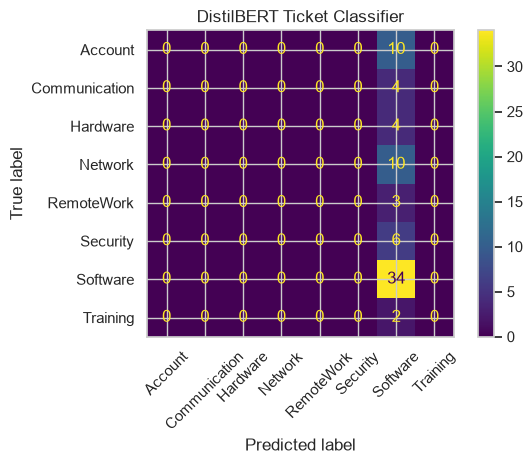

In [138]:
ConfusionMatrixDisplay.from_predictions(
    label_encoder.inverse_transform(y_val_encoded),
    label_encoder.inverse_transform(transformer_val_pred),
    labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("DistilBERT Ticket Classifier")
plt.tight_layout()
plt.show()

In [141]:
from transformers import set_seed

set_seed(42)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_encoder.classes_),
    id2label=id2label,
    label2id=label2id
)

training_args = TrainingArguments(
    output_dir="../models/second_distilbert_ticket_classifier",

    learning_rate=5e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=10,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=10,

    save_total_limit=2,

    seed=42,

    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Weighted F1,Macro F1
1,1.552505,1.577922,0.465753,0.295993,0.079439
2,1.318287,1.214047,0.630137,0.546678,0.253773
3,0.896356,1.004284,0.698630,0.644077,0.411387
4,0.602596,0.820268,0.767123,0.736129,0.610261
5,0.343919,0.870130,0.794521,0.781424,0.672414
6,0.211370,0.800583,0.767123,0.755496,0.636263
7,0.111036,0.805896,0.794521,0.784562,0.696843
8,0.134351,0.845226,0.780822,0.769341,0.656261
9,0.073812,0.845695,0.780822,0.770750,0.676855
10,0.053392,0.850432,0.780822,0.770750,0.676855


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=220, training_loss=0.5648526021025397, metrics={'train_runtime': 39.9829, 'train_samples_per_second': 85.787, 'train_steps_per_second': 5.502, 'total_flos': 113084148821520.0, 'train_loss': 0.5648526021025397, 'epoch': 10.0})

               precision    recall  f1-score   support

      Account       0.58      0.70      0.64        10
Communication       0.67      0.50      0.57         4
     Hardware       1.00      0.75      0.86         4
      Network       0.90      0.90      0.90        10
   RemoteWork       1.00      1.00      1.00         3
     Security       0.71      0.83      0.77         6
     Software       0.83      0.85      0.84        34
     Training       0.00      0.00      0.00         2

     accuracy                           0.79        73
    macro avg       0.71      0.69      0.70        73
 weighted avg       0.78      0.79      0.78        73



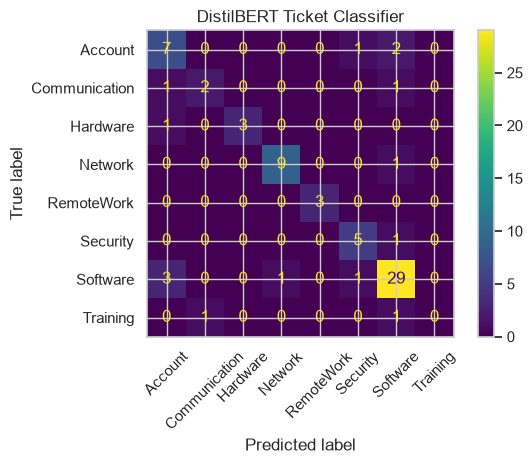

In [142]:
prediction_output = trainer.predict(tokenized_val)

transformer_val_pred = np.argmax(
    prediction_output.predictions,
    axis=1
)

print(
    classification_report(
        y_val_encoded,
        transformer_val_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    label_encoder.inverse_transform(y_val_encoded),
    label_encoder.inverse_transform(transformer_val_pred),
    labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("DistilBERT Ticket Classifier")
plt.tight_layout()
plt.show()

In [145]:
from sklearn.utils.class_weight import compute_class_weight
import torch.nn.functional as F

train_labels = np.asarray(y_train_encoded)
classes = np.arange(len(label_encoder.classes_))

# Standard inverse-frequency balanced weights
balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

# Soften them
soft_weights = np.sqrt(balanced_weights)

# Keep the average sample weight around 1.
# This mostly keeps the overall loss scale comparable.
soft_weights = soft_weights / np.mean(soft_weights[train_labels])

soft_weights_tensor = torch.tensor(
    soft_weights,
    dtype=torch.float32
)

for class_name, weight in zip(label_encoder.classes_, soft_weights):
    print(f"{class_name:15s}: {weight:.3f}")

Account        : 1.039
Communication  : 1.782
Hardware       : 1.897
Network        : 1.061
RemoteWork     : 1.964
Security       : 1.365
Software       : 0.577
Training       : 2.598


In [146]:
def weighted_loss(outputs, labels, num_items_in_batch=None):
    logits = outputs.logits

    weights = soft_weights_tensor.to(logits.device)

    return F.cross_entropy(
        logits,
        labels,
        weight=weights
    )

from transformers import set_seed

set_seed(42)

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_encoder.classes_),
    id2label=id2label,
    label2id=label2id
)

weighted_training_args = TrainingArguments(
    output_dir="../models/weighted_distilbert_ticket_classifier",

    learning_rate=5e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=10,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=10,

    save_total_limit=2,

    seed=42,
    report_to="none"
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [147]:
weighted_trainer = Trainer(
    model=weighted_model,
    args=weighted_training_args,

    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics,

    # changing loss to weighted loss
    compute_loss_func=weighted_loss
)

weighted_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Weighted F1,Macro F1
1,1.927756,1.933420,0.465753,0.295993,0.079439
2,1.698268,1.609869,0.575342,0.498624,0.237604
3,1.263476,1.259246,0.739726,0.707377,0.558873
4,0.840630,1.012272,0.767123,0.756164,0.646465
5,0.470166,0.991317,0.726027,0.713242,0.621667
6,0.308820,0.961805,0.780822,0.777560,0.734136
7,0.159104,0.920274,0.808219,0.802626,0.767824
8,0.138602,1.014551,0.808219,0.802626,0.767824
9,0.084233,0.995248,0.808219,0.802626,0.767824
10,0.065600,1.015276,0.808219,0.802626,0.767824


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=220, training_loss=0.7270058174024928, metrics={'train_runtime': 39.6666, 'train_samples_per_second': 86.471, 'train_steps_per_second': 5.546, 'total_flos': 113084148821520.0, 'train_loss': 0.7270058174024928, 'epoch': 10.0})

Training Loss,Validation Loss,Epoch,Accuracy,Weighted F1,Macro F1
0.065600,0.920274,10,0.808219,0.802626,0.767824


               precision    recall  f1-score   support

      Account       0.54      0.70      0.61        10
Communication       1.00      0.25      0.40         4
     Hardware       1.00      0.75      0.86         4
      Network       0.90      0.90      0.90        10
   RemoteWork       1.00      1.00      1.00         3
     Security       0.75      1.00      0.86         6
     Software       0.85      0.85      0.85        34
     Training       1.00      0.50      0.67         2

     accuracy                           0.81        73
    macro avg       0.88      0.74      0.77        73
 weighted avg       0.83      0.81      0.80        73



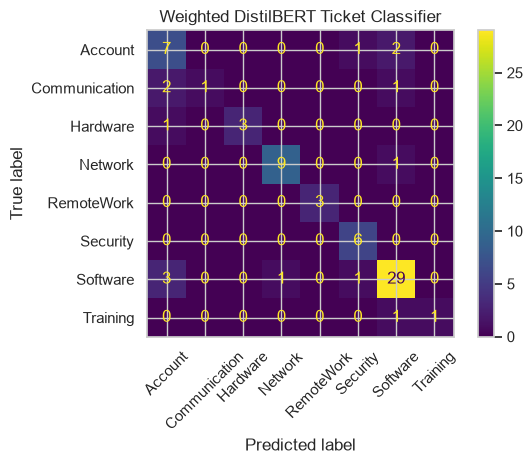

In [148]:
weighted_val_metrics = weighted_trainer.evaluate(tokenized_val)

weighted_val_metrics

weighted_output = weighted_trainer.predict(tokenized_val)

weighted_transformer_val_pred = np.argmax(
    weighted_output.predictions,
    axis=1
)

print(
    classification_report(
        y_val_encoded,
        weighted_transformer_val_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    label_encoder.inverse_transform(y_val_encoded),
    label_encoder.inverse_transform(weighted_transformer_val_pred),
    labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("Weighted DistilBERT Ticket Classifier")
plt.tight_layout()
plt.show()

The weighted DistilBERT model improved overall performance over both its unweighted counterpart and TF-IDF model which triumphed the PyTorch implementation. By adding class weighting we further improved macro F1 from 0.697 to 768 while the accuracy increased to 0.808 and weighted F1 to 0.803.

In [149]:
MODEL_DIR = "../models/weighted_distilbert"

weighted_trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('../models/weighted_distilbert\\tokenizer_config.json',
 '../models/weighted_distilbert\\tokenizer.json')